![Logo](LogoCab.png)

<div style="background-color: #FFFFFF; padding: 35px 40px; border-radius: 8px; font-family: 'Montserrat', 'Helvetica Neue', Helvetica, Arial, sans-serif; border: 1px solid #D9CEB5; margin-top: 20px; box-shadow: 0 2px 10px rgba(0,0,0,0.02);">

  <h3 style="color: #2C3034; font-size: 20px; font-weight: 700; margin-top: 0px; margin-bottom: 15px; letter-spacing: 0.5px;">
    1. Introduction and Project Context
  </h3>

  <p style="color: #4A4F55; font-size: 14px; line-height: 1.6; margin-bottom: 15px;">
Amazing Creative Desk Coworking (ACDC) operates in a competitive coworking market with a diverse member base, where customers can differ considerably in terms of their membership plans, usage patterns, and engagement with the available services. Understanding these differences is important for identifying distinct customer groups and developing strategies that better respond to their needs.
 </p>

  <p style="color: #4A4F55; font-size: 14px; line-height: 1.6; margin-bottom: 15px;">
    This project focuses on the analysis of ACDC’s membership and space-usage data collected over a three-year period. By exploring customer characteristics, membership information, and behavioural patterns, the aim is to identify meaningful segments within the customer base. These insights can then be used to support a more targeted marketing strategy, helping ACDC improve customer satisfaction, retention, and overall business performance. 
</p>

  <p style="color: #4A4F55; font-size: 14px; line-height: 1.6; margin-bottom: 0px;">
The analysis follows a data-driven approach to customer segmentation, considering different perspectives such as customer value and usage behaviour. The results of this analysis will provide the basis for the subsequent clustering process and the development of actionable business recommendations.
</p>

</div>


<div style="background-color: #FFFFFF; padding: 35px 40px; border-radius: 8px; font-family: 'Montserrat', 'Helvetica Neue', Helvetica, Arial, sans-serif; border: 1px solid #D9CEB5; margin-top: 20px; box-shadow: 0 2px 10px rgba(0,0,0,0.02);">

  <h3 style="color: #2C3034; font-size: 20px; font-weight: 700; margin-top: 0px; margin-bottom: 15px; letter-spacing: 0.5px;">
    2. Importing Libraries and Loading Data
  </h3>

  <p style="color: #4A4F55; font-size: 14px; line-height: 1.6; margin-bottom: 15px;">
Descriçãozinha
 </p>

</div>

In [1]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

from itertools import product
from ydata_profiling import ProfileReport

%config InlineBackend.figure_format = 'retina'

np.random.seed(40311)
sns.set()

C:\Users\maria\AppData\Local\Temp\ipykernel_23680\1134609971.py:10: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


# Import Dataset

In [6]:
dataset = pd.read_csv(r"..\..\ACDC_DM\data\acdc_dataset.csv",sep=";", index_col= 'member_id')

# Exploratory Data Analysis (EDA)

In [7]:
print('Dataset shape:', df.shape)

Dataset shape: (15465, 30)


In [8]:
dataset.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [9]:
dataset.tail()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,...,False,False,1,True,True,False,False,False,0,1422.36
CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,...,False,False,0,True,True,False,True,False,0,20683.24
CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,...,False,False,0,False,False,False,False,False,0,18.14
CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,...,True,False,1,False,True,True,True,False,4,11834.5
CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,...,False,False,0,False,False,False,False,False,0,435.82


In [10]:
dataset.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

In [11]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In [12]:
dataset.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,14907.0,NaN,NaN,NaN,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
gender,14935,12,Female,7414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
industry,15465,43,Information Technology,3322,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,15035,33,Portugal,9959,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_team_account,15465,2,False,11112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_colleagues_on_account,15465.0,NaN,NaN,NaN,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_tier,15360,19,flex,5182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_days_per_week,15465.0,NaN,NaN,NaN,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
membership_start,15465,1539,2021-01-01,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
membership_end,15465,1423,1970-01-01,3956,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
summary_uniqueNonNulls = pd.DataFrame({
    "Non-null values": dataset.count(),
    "Unique non-null values": dataset.nunique()
})

summary_uniqueNonNulls

,Non-null values,Unique non-null values
age,14907,84
gender,14935,12
industry,15465,43
country,15035,33
is_team_account,15465,2
n_colleagues_on_account,15465,11
plan_tier,15360,19
plan_days_per_week,15465,6
membership_start,15465,1539
membership_end,15465,1423


# Structural Survey

# Distribution Statistics

In [16]:
numeric_features = df.select_dtypes(include=['number'])

numeric_stats = numeric_features.describe().T

numeric_stats

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [17]:
numeric_columns = df.select_dtypes(include=['number']).columns

for column in numeric_columns:
    series = df[column]
    
    print(f"--------------------------------------------------")
    print(f"Feature: {column}")
    print("Missing values:", series.isna().sum())
    print("Negative values:", (series < 0).sum())
    print("Largest 5 values:", series.nlargest(5).to_list())

--------------------------------------------------
Feature: age
Missing values: 558
Negative values: 0
Largest 5 values: [149.0, 147.0, 146.0, 146.0, 145.0]
--------------------------------------------------
Feature: n_colleagues_on_account
Missing values: 0
Negative values: 566
Largest 5 values: [9, 8, 8, 7, 7]
--------------------------------------------------
Feature: plan_days_per_week
Missing values: 0
Negative values: 0
Largest 5 values: [9, 9, 9, 9, 9]
--------------------------------------------------
Feature: days_since_last_visit
Missing values: 0
Negative values: 56
Largest 5 values: [1212, 1147, 1004, 1003, 1002]
--------------------------------------------------
Feature: total_visits
Missing values: 0
Negative values: 42
Largest 5 values: [6530, 4880, 4750, 2640, 1790]
--------------------------------------------------
Feature: avg_weekly_visits
Missing values: 0
Negative values: 0
Largest 5 values: [47.4, 46.5, 44.5, 43.3, 43.2]
-------------------------------------------

# Data Quality

In [15]:
def check_missing(df, name="Dataset"):
    missing_values = df.isna().sum()
    percentage = df.isna().mean() * 100
    result = pd.DataFrame({
        "Missing Count": missing_values,
        "Missing %": percentage
    })
    if result["Missing Count"].sum() == 0:
        print(f"No missing values in {name}!")
    else:
        print(f"Missing values in {name}:")
        display(result[ result["Missing Count"] > 0 ]) 


check_missing(df, "Dataset")

Missing values in Dataset:


,Missing Count,Missing %
age,558,3.608147
gender,530,3.427093
country,430,2.780472
plan_tier,105,0.678952
meeting_room_hours,1298,8.393146
guest_passes_issued,1271,8.218558
lifetime_value,1040,6.724863


In [19]:
numeric_columns = df.select_dtypes(include=['number']).columns

for column in numeric_columns:
    series = df[column]
    
    print(f"--------------------------------------------------")
    print(f"Feature: {column}")
    print("Missing values:", series.isna().sum())
    print("Negative values:", (series < 0).sum())
    print("Largest 5 values:", series.nlargest(5).to_list())

--------------------------------------------------
Feature: age
Missing values: 558
Negative values: 0
Largest 5 values: [149.0, 147.0, 146.0, 146.0, 145.0]
--------------------------------------------------
Feature: n_colleagues_on_account
Missing values: 0
Negative values: 566
Largest 5 values: [9, 8, 8, 7, 7]
--------------------------------------------------
Feature: plan_days_per_week
Missing values: 0
Negative values: 0
Largest 5 values: [9, 9, 9, 9, 9]
--------------------------------------------------
Feature: days_since_last_visit
Missing values: 0
Negative values: 56
Largest 5 values: [1212, 1147, 1004, 1003, 1002]
--------------------------------------------------
Feature: total_visits
Missing values: 0
Negative values: 42
Largest 5 values: [6530, 4880, 4750, 2640, 1790]
--------------------------------------------------
Feature: avg_weekly_visits
Missing values: 0
Negative values: 0
Largest 5 values: [47.4, 46.5, 44.5, 43.3, 43.2]
-------------------------------------------

## Row-level analysis

In [21]:
duplicate_count = dataset.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

Number of duplicated rows: 182


# Relationships between variables

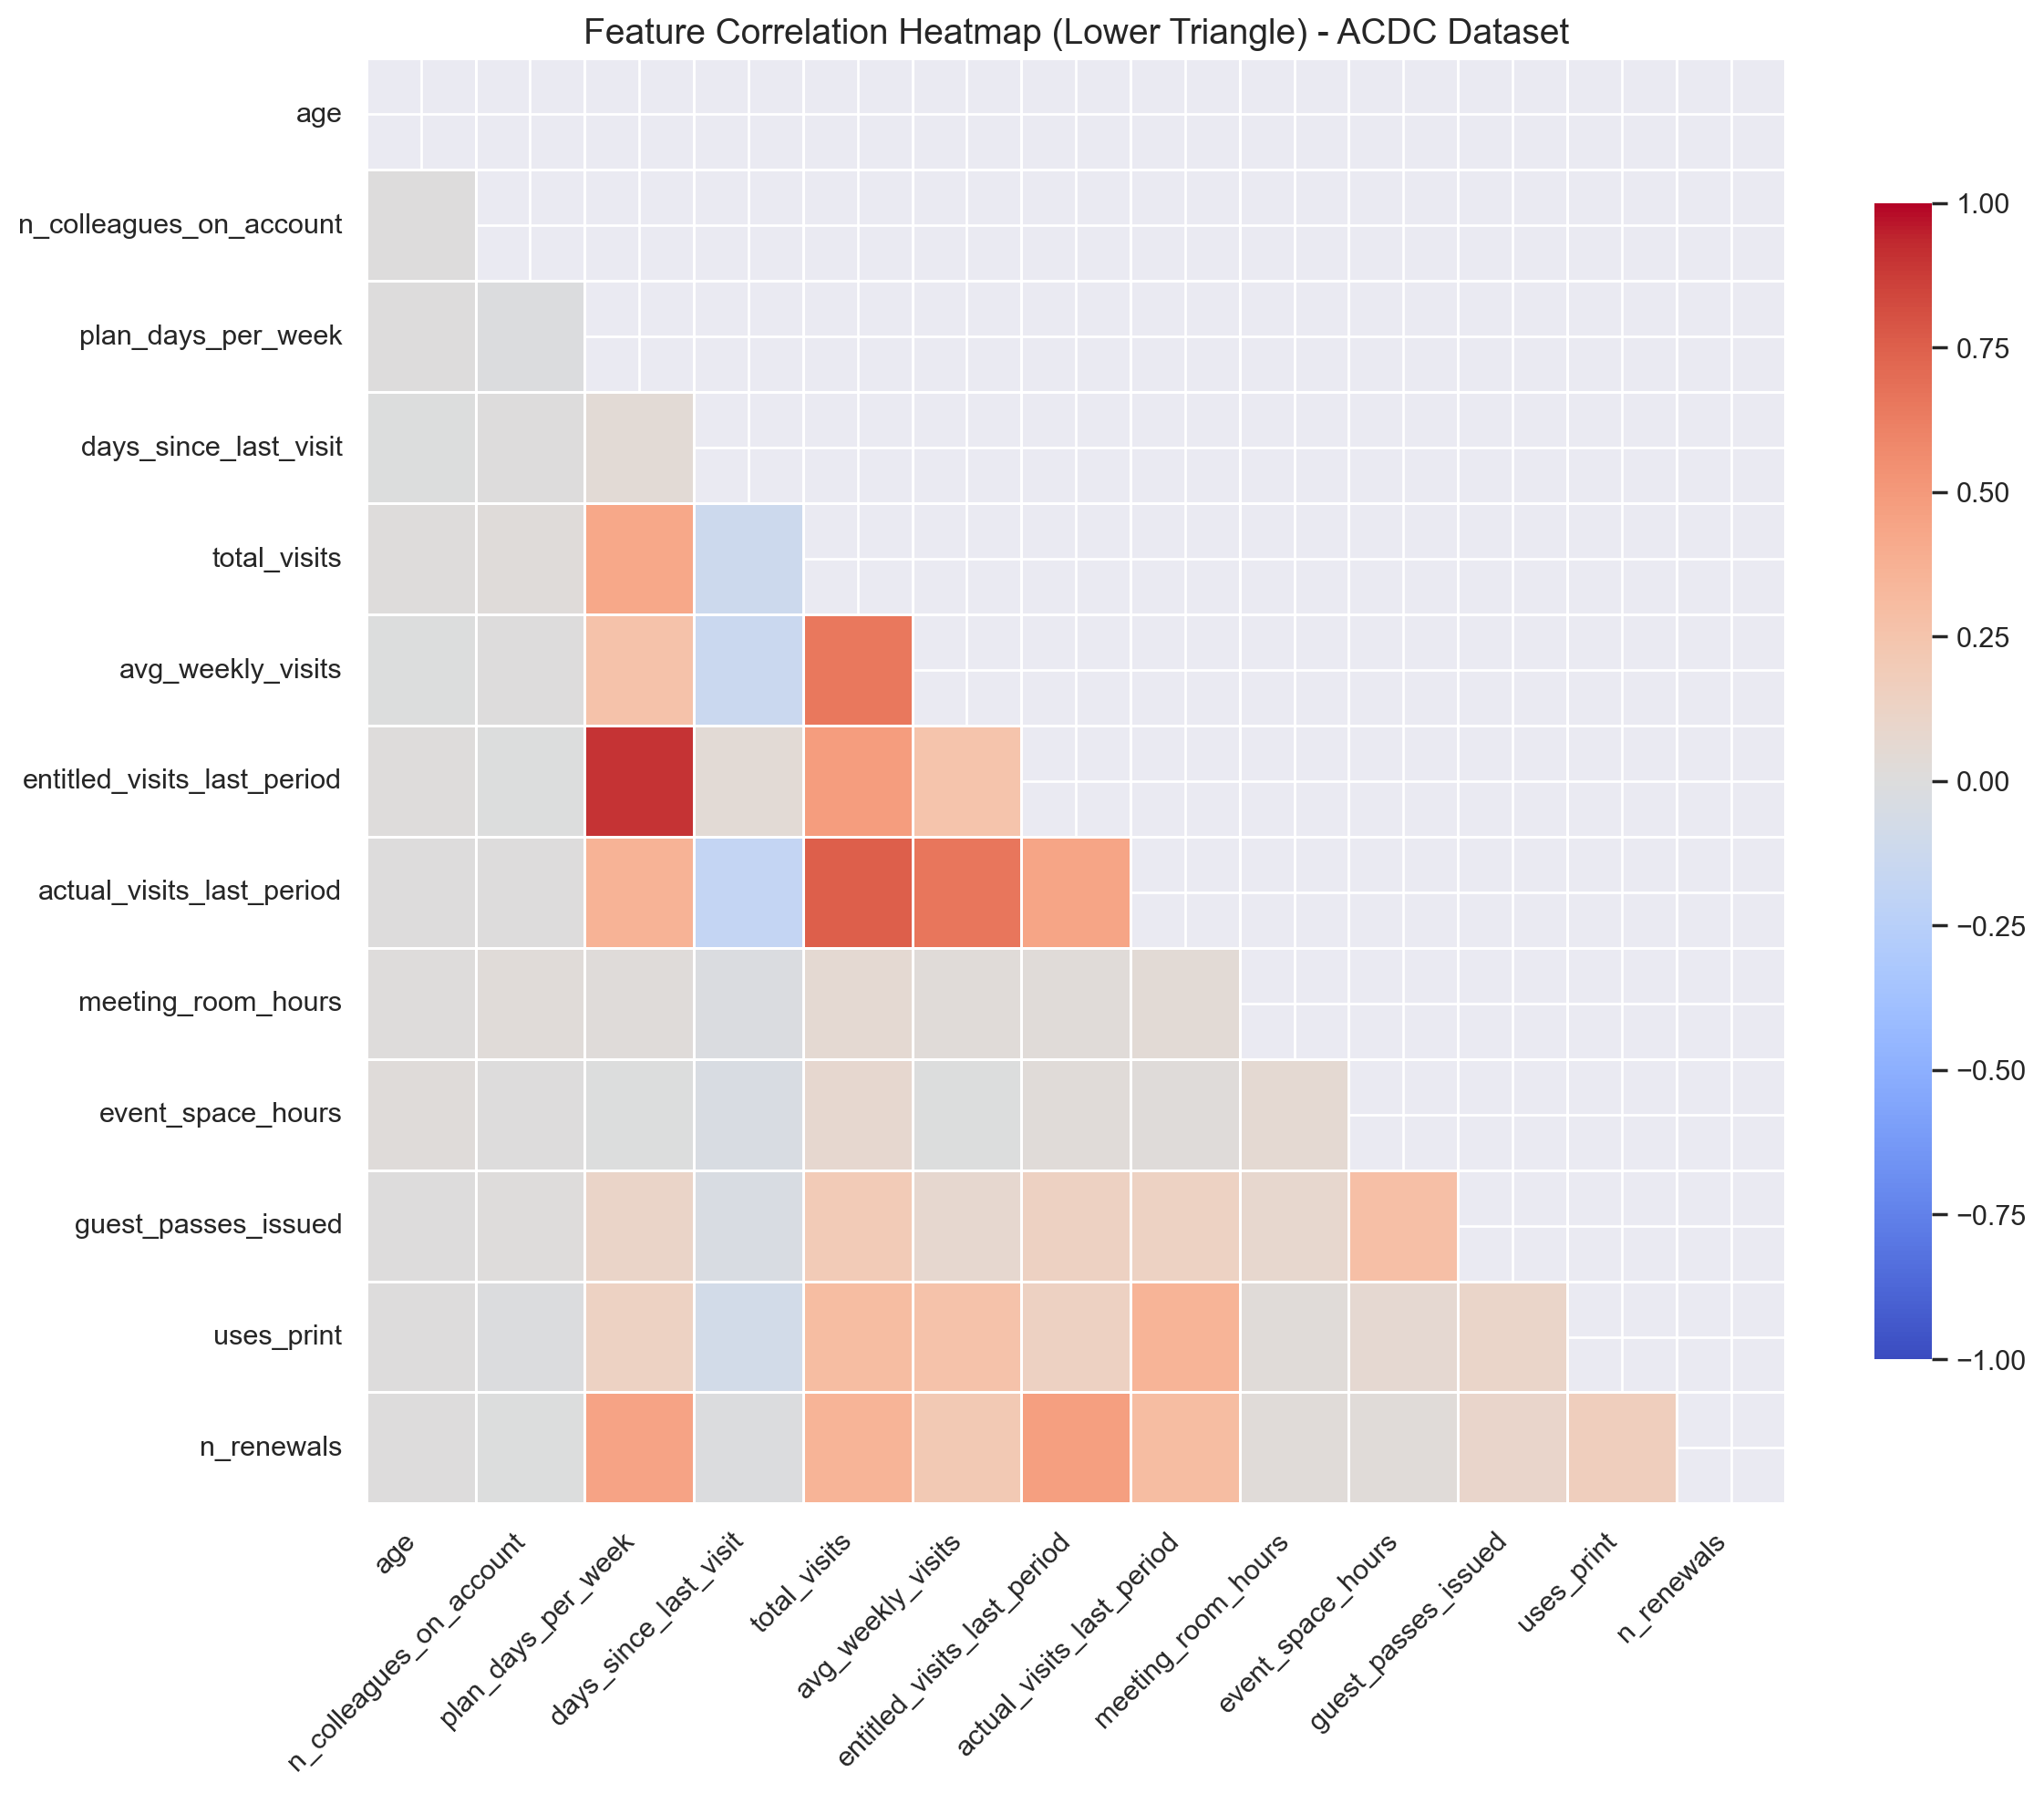

In [25]:
# 1. Selecionar colunas numéricas e calcular a correlação
numeric_df = df.select_dtypes(include=['number'])
correlation_matrix = numeric_df.corr()

# 2. Criar uma máscara para ocultar a metade superior (o espelho)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# 3. Configurar a figura
plt.figure(figsize=(12, 10))

# 4. Gerar o heatmap apenas com a metade inferior
sns.heatmap(
    correlation_matrix, 
    mask=mask, 
    annot=False,          # Põe True se quiseres ver os números nas caixas (se forem poucas colunas)
    cmap='coolwarm', 
    vmin=-1, vmax=1,      # Garante que a escala varia rigorosamente de -1 a 1
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Feature Correlation Heatmap (Lower Triangle) - ACDC Dataset', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

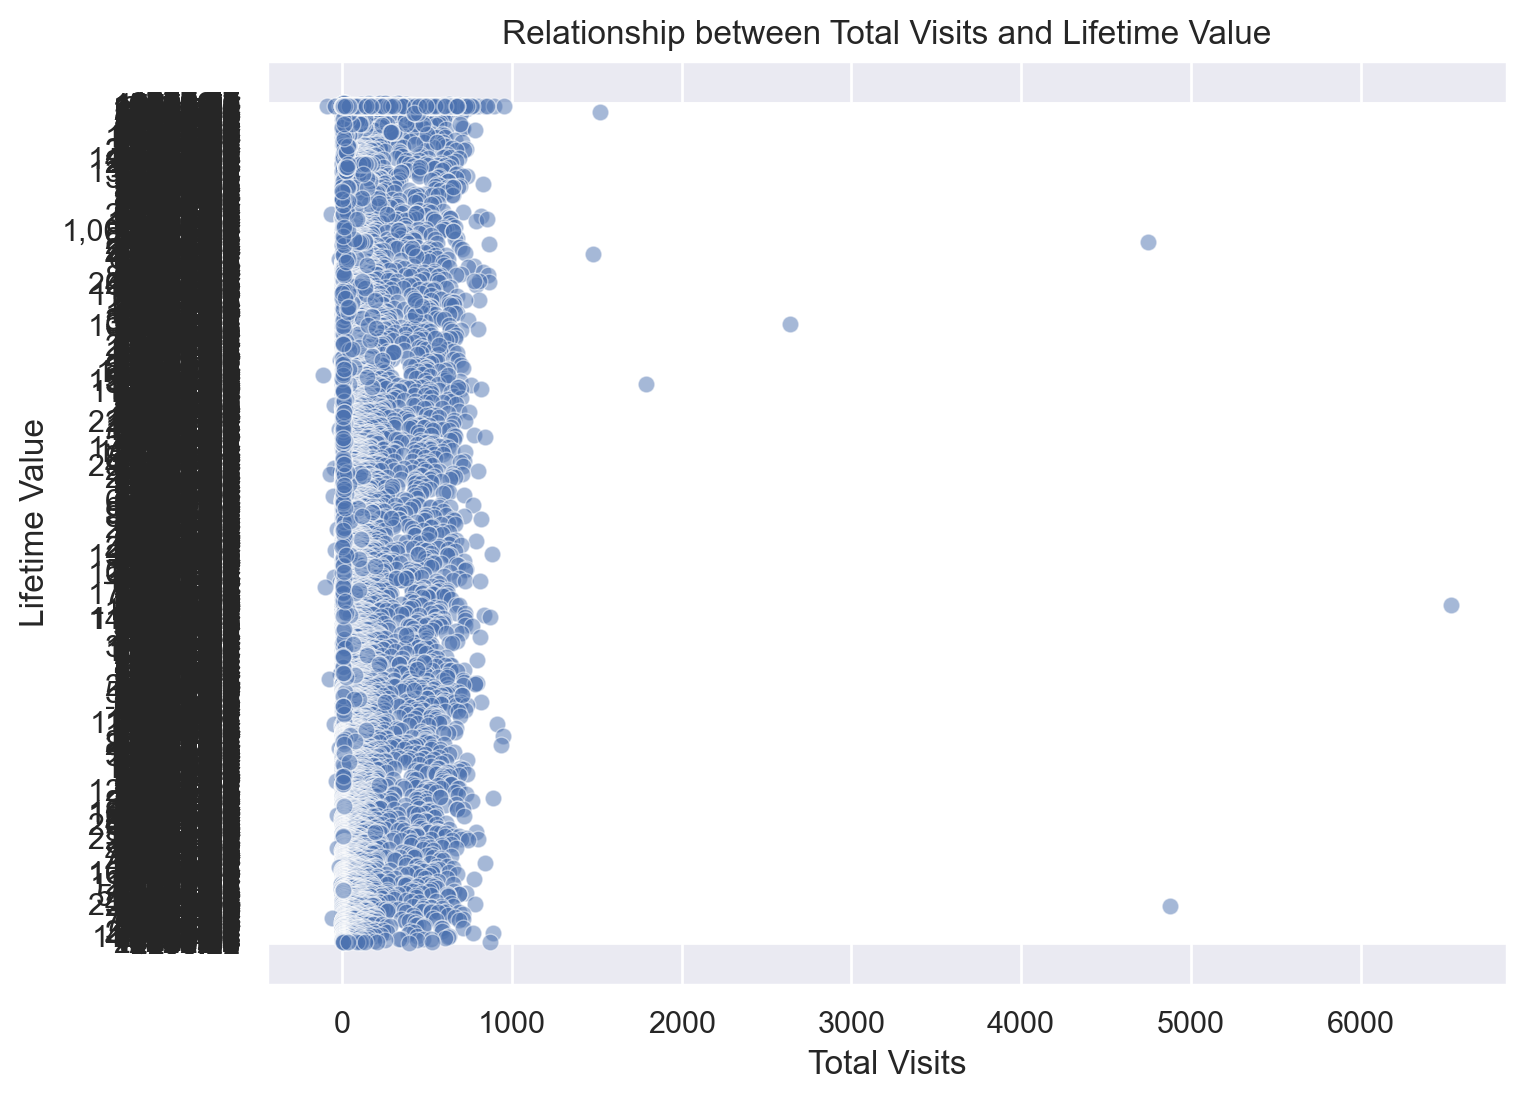

In [27]:
# 1. Garantir que removes os duplicados
df.drop_duplicates(inplace=True)

# 2. Resetar o índice para evitar índices duplicados (caso o member_id estivesse como índice)
df = df.reset_index(drop=True)

# 3. Agora já podes fazer o scatter plot sem erros
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='total_visits', y='lifetime_value', alpha=0.5)
plt.title('Relationship between Total Visits and Lifetime Value')
plt.xlabel('Total Visits')
plt.ylabel('Lifetime Value')
plt.show()

# por organizar, ver se faz sentido manter

In [16]:
for column in df.columns:
    unique_values = df[column].unique()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

Unique values on the column 'age': [ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]
-----------------------------------

Unique values on the column 'gender': ['Female' 'Male' 'F' 'Other' nan ' Female' 'M' 'male' ' Male' 'other'
 ' Other' 'female' 'O']
-----------------------------------

Unique values on the column 'industry': ['Information Technology' 'Education' 'Legal' 'Health' 'Unknown' 'Other'
 'Consulting' 'Design & Creative' 'information technology' 'Finance'
 'Marketing & PR' 'EDUCATION' 'DESIGN & CREATIVE' 'Marketing and PR'
 'Real Estate' 'other' 'consulting' 'MARKETING & PR'
 'Information technolo

In [17]:
for column in df.columns:
    unique_values = df[column].value_counts()
    print(f"The number of the distinct values in the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

The number of the distinct values in the column 'age': age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
        ... 
92.0       1
139.0      1
143.0      1
91.0       1
149.0      1
Name: count, Length: 84, dtype: int64
-----------------------------------

The number of the distinct values in the column 'gender': gender
Female     7414
Male       6172
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64
-----------------------------------

The number of the distinct values in the column 'industry': industry
Information Technology    3322
Consulting                1896
Marketing & PR            1835
Design & Creative         1822
Finance                   1134
Other                     1100
Legal                      809
Education                  727
Unknown                    640
Health                     571
Real Estate             

In [18]:
#Check how many duplicates exist
print(df.duplicated().sum())

#check the percentage of duplicates in our DataFrame
print(df.duplicated().sum() / len(df) * 100)

182
1.1768509537665697


In [21]:
df = pd.read_csv(r"C:\Users\maria\Desktop\NOVA IMS\1st year\1st semester\Data Mining\ACDC_DM\data\acdc_dataset.csv",sep=";")

df.duplicated().sum() / len(df) * 100

# para ver os duplicados não se pode ter o index member id

np.float64(0.09699321047526674)

In [23]:
# Find all member_id values that appear more than once
duplicate_ids = df[df['member_id'].duplicated(keep=False)]['member_id'].unique()

print("The member IDs with duplicates are:")
print(duplicate_ids)

# Check all rows associated with a specific duplicate ID (e.g., the first one)
example_id = duplicate_ids[0]
display(df[df["member_id"] == example_id])

The member IDs with duplicates are:
['CW015101' 'CW000935' 'CW001390' 'CW003868' 'CW005287' 'CW005845'
 'CW006678' 'CW007196' 'CW008814' 'CW009043' 'CW009828' 'CW011277'
 'CW012056' 'CW013132' 'CW014953']


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
606,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82


In [27]:
example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW015101"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW000935"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW001390"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW003868"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW005287"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW005845"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW006678"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW007196"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW008814"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW009043"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW009828"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW011277"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW012056"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW013132"])

example_id = duplicate_ids[0]
display(df[df["member_id"] == "CW014953"])

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
606,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
5441,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24


...

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
10113,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,...,False,False,1,True,True,False,False,False,0,1422.36
15460,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,...,False,False,1,True,True,False,False,False,0,1422.36


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
11610,CW011277,35.0,Male,Consulting,NaN,False,0,full_time,5,2022-03-20,...,False,False,0,False,True,False,False,False,0,2647.86
15459,CW011277,35.0,Male,Consulting,NaN,False,0,full_time,5,2022-03-20,...,False,False,0,False,True,False,False,False,0,2647.86


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
12416,CW012056,21.0,Male,Real Estate,Portugal,False,0,flex,3,2022-01-16,...,True,False,0,False,False,True,False,False,0,418.74
15455,CW012056,21.0,Male,Real Estate,Portugal,False,0,flex,3,2022-01-16,...,True,False,0,False,False,True,False,False,0,418.74


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
13528,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,...,True,False,1,False,True,True,True,False,4,11834.5
15463,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,...,True,False,1,False,True,True,True,False,4,11834.5


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
15401,CW014953,37.0,Female,Consulting,United Kingdom,False,0,fulltime,5,25/02/2021,...,False,False,1,False,False,False,False,False,0,0
15458,CW014953,37.0,Female,Consulting,United Kingdom,False,0,fulltime,5,25/02/2021,...,False,False,1,False,False,False,False,False,0,0


In [28]:
df.drop_duplicates(inplace=True)

print("Remaining duplicates count:", df.duplicated().sum())

print("New dataset shape:", df.shape)

Remaining duplicates count: 0
New dataset shape: (15450, 31)


In [29]:
for column in df.columns:
    unique_values = df[column].value_counts()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')


Unique values on the column 'member_id': member_id
CW000001    1
CW000002    1
CW000003    1
CW000004    1
CW000005    1
           ..
CW014996    1
CW014997    1
CW014998    1
CW014999    1
CW015000    1
Name: count, Length: 15450, dtype: int64
-----------------------------------

Unique values on the column 'age': age
34.0     710
31.0     679
32.0     657
36.0     655
35.0     648
        ... 
92.0       1
139.0      1
143.0      1
91.0       1
149.0      1
Name: count, Length: 84, dtype: int64
-----------------------------------

Unique values on the column 'gender': gender
Female     7405
Male       6166
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64
-----------------------------------

Unique values on the column 'industry': industry
Information Technology    3320
Consulting                1893
Marketing & PR            1834
Design & Creative 